# Module project: build a GAN that draws clothes

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-1-fashion-gan.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-5-generative/files/project-1-fashion-gan.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/fashion-gan` folder in the course files, to check your work.
- **Data**: Fashion-MNIST (Zalando Research). Source: [https://github.com/zalandoresearch/fashion-mnist/tree/master/data/fashion](https://github.com/zalandoresearch/fashion-mnist/tree/master/data/fashion) · about: [https://github.com/zalandoresearch/fashion-mnist](https://github.com/zalandoresearch/fashion-mnist) · licence: MIT. `data.py` downloads it the first time you run it and keeps it in `data/`: `t10k-images-idx3-ubyte.gz`, `t10k-labels-idx1-ubyte.gz`, `train-images-idx3-ubyte.gz`, `train-labels-idx1-ubyte.gz`, 29.4 MB.

In [ ]:
%pip install -q torch matplotlib

In the Build lesson you watched a one-dimensional GAN collapse onto a single value, then fixed it. Now the real thing: a
GAN that learns to draw clothes from the 60,000 photos of Fashion-MNIST. You'll also solve the problem section 17.1.2
raises, that GAN losses don't tell you how good the pictures are, by building an independent **judge** that measures
quality, variety and copying.

## What you'll build

```mermaid
flowchart LR
    Z[random z<br/>64 numbers] --> G[generator]
    G --> F[fake image]
    R[real photo] --> D[discriminator]
    F --> D
    D --> L[real or fake?]
    F --> J[judge CNN:<br/>quality, variety,<br/>copying]
```

## Set up the project

```bash
mkdir fashion-gan && cd fashion-gan
python -m venv .venv && source .venv/bin/activate
pip install torch matplotlib
git init
```

Copy `data.py` from your part 1 clothes classifier.

```text
fashion-gan/
    .gitignore
    README.md
    data.py
    evaluate.py
    generator.pt
    models.py
    requirements.txt
    runcache.json
    train.py
```

In [ ]:
%%writefile requirements.txt
torch
matplotlib

Writing requirements.txt


In [ ]:
%%writefile .gitignore
data/
outputs/*
!outputs/*.png
__pycache__/
*.pt
.venv/

Writing .gitignore


In [ ]:
%%writefile data.py
"""Fashion-MNIST: 70,000 grey 28x28 photos of clothes in 10 classes (Zalando Research)."""
from pathlib import Path
from urllib.request import urlopen
import gzip
import torch

URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CLASSES = ["T-shirt", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "ankle boot"]


def _read(name, offset):
    path = Path("data") / name
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        path.write_bytes(urlopen(URL + name).read())
    raw = gzip.decompress(path.read_bytes())
    return torch.frombuffer(bytearray(raw[offset:]), dtype=torch.uint8)


def load(split):
    """split: 'train' (60,000 images) or 't10k' (10,000). Returns images as (N, 784) floats in [0, 1] and labels."""
    x = _read(f"{split}-images-idx3-ubyte.gz", 16).reshape(-1, 784).float() / 255
    t = _read(f"{split}-labels-idx1-ubyte.gz", 8).long()
    return x, t


def load_splits():
    x, t = load("train")
    g = torch.Generator().manual_seed(0)
    order = torch.randperm(len(x), generator=g)
    val, train = order[:10000], order[10000:]
    return (x[train], t[train]), (x[val], t[val]), load("t10k")


if __name__ == "__main__":
    (xtr, ttr), (xva, tva), (xte, tte) = load_splits()
    print(f"train {len(xtr)}, validation {len(xva)}, test {len(xte)} images of {xtr.shape[1]} pixels")
    print("images per class in training:", torch.bincount(ttr).tolist())

Writing data.py


## Step 1: two networks

The generator turns 64 random numbers into a 28 × 28 image through two hidden layers; its last layer is `tanh`, so pixels
land in [−1, 1], and the real images are rescaled to match. The discriminator is an ordinary classifier with a single
output, a logit for "real". `LeakyReLU` (a small slope for negative inputs instead of zero) and dropout in the
discriminator are standard choices that keep gradients flowing and stop the discriminator from winning too easily.

In [ ]:
%%writefile models.py
"""A generator and a discriminator (Bishop, section 17.1): two networks trained against each other."""
from torch import nn

Z = 64                                           # size of the random input vector


def generator():
    """Random vector z (64 numbers) -> a 28x28 image, pixels in [-1, 1]."""
    return nn.Sequential(nn.Linear(Z, 256), nn.LeakyReLU(0.2),
                         nn.Linear(256, 512), nn.BatchNorm1d(512), nn.LeakyReLU(0.2),
                         nn.Linear(512, 784), nn.Tanh())


def discriminator():
    """Image -> one score (a logit): high means 'this looks like a real photo'."""
    return nn.Sequential(nn.Linear(784, 512), nn.LeakyReLU(0.2), nn.Dropout(0.3),
                         nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Dropout(0.3),
                         nn.Linear(256, 1))

Writing models.py


## Step 2: the game

Each step has two moves, exactly as in the Build lesson:

1. **The discriminator** learns to tell a batch of real photos (target 1) from a batch of fakes (target 0), with the
   cross-entropy of equation 17.6. Note `fake.detach()`: this step must not change the generator.
2. **The generator** learns to make the discriminator answer 1 for its fakes: the non-saturating loss (equation 17.10).

Adam with `betas=(0.5, 0.999)` (less momentum than the default) is the classic setting for GANs.

In [ ]:
%%writefile train.py
"""Train the GAN on Fashion-MNIST, saving a grid of generated images after some epochs."""
import argparse
from pathlib import Path
import torch
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from data import load
from models import generator, discriminator, Z

ap = argparse.ArgumentParser()
ap.add_argument("--epochs", type=int, default=15)
args = ap.parse_args()
torch.manual_seed(0)
x, _ = load("train")
x = x * 2 - 1                                       # pixels in [-1, 1], to match the generator's tanh
G, D = generator(), discriminator()
opt_g = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
fixed_z = torch.randn(64, Z, generator=torch.Generator().manual_seed(1))   # the same 64 inputs every time
Path("outputs").mkdir(exist_ok=True)


def save_grid(epoch):
    G.eval()
    with torch.no_grad():
        imgs = G(fixed_z).reshape(-1, 28, 28)
    G.train()
    fig, axes = plt.subplots(8, 8, figsize=(6, 6))
    for img, ax in zip(imgs, axes.flat):
        ax.imshow(img, cmap="gray", vmin=-1, vmax=1); ax.axis("off")
    fig.suptitle(f"after {epoch} epochs"); fig.tight_layout()
    fig.savefig(f"outputs/epoch_{epoch:02d}.png", dpi=80); plt.close(fig)


for epoch in range(1, args.epochs + 1):
    order = torch.randperm(len(x))
    for s in range(0, len(x) - 127, 128):
        real = x[order[s:s + 128]]
        fake = G(torch.randn(128, Z))
        # 1. discriminator: push real towards 1 and fake towards 0 (the cross-entropy of equation 17.6)
        d_loss = F.binary_cross_entropy_with_logits(D(real), torch.ones(128, 1)) + \
                 F.binary_cross_entropy_with_logits(D(fake.detach()), torch.zeros(128, 1))
        opt_d.zero_grad(); d_loss.backward(); opt_d.step()
        # 2. generator: make the discriminator say 1 for fakes (the non-saturating version, equation 17.10)
        g_loss = F.binary_cross_entropy_with_logits(D(fake), torch.ones(128, 1))
        opt_g.zero_grad(); g_loss.backward(); opt_g.step()
    with torch.no_grad():
        d_real = torch.sigmoid(D(real)).mean().item(); d_fake = torch.sigmoid(D(fake)).mean().item()
    print(f"epoch {epoch:2d}: D says real {d_real:.2f}, fake {d_fake:.2f}   losses D {d_loss.item():.2f}, G {g_loss.item():.2f}")
    if epoch in (1, 3, 8, args.epochs):
        save_grid(epoch)
torch.save(G.state_dict(), "generator.pt")

Writing train.py


In [ ]:
!python train.py

epoch  1: D says real 0.71, fake 0.35   losses D 1.12, G 1.13
epoch  2: D says real 0.64, fake 0.40   losses D 1.22, G 1.02
epoch  3: D says real 0.70, fake 0.39   losses D 1.11, G 1.10
epoch  4: D says real 0.64, fake 0.35   losses D 1.05, G 1.19
epoch  5: D says real 0.61, fake 0.34   losses D 1.12, G 1.19
epoch  6: D says real 0.70, fake 0.46   losses D 1.15, G 0.95
epoch  7: D says real 0.60, fake 0.36   losses D 1.09, G 1.13
epoch  8: D says real 0.67, fake 0.38   losses D 1.06, G 1.01
epoch  9: D says real 0.60, fake 0.36   losses D 1.11, G 1.08
epoch 10: D says real 0.58, fake 0.38   losses D 1.21, G 1.15
epoch 11: D says real 0.59, fake 0.36   losses D 1.11, G 1.09
epoch 12: D says real 0.62, fake 0.41   losses D 1.22, G 0.97
epoch 13: D says real 0.59, fake 0.39   losses D 1.26, G 0.98
epoch 14: D says real 0.60, fake 0.44   losses D 1.24, G 0.98
epoch 15: D says real 0.59, fake 0.42   losses D 1.25, G 0.93


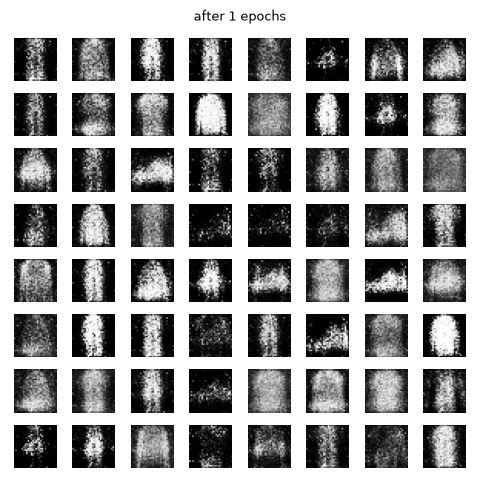

In [ ]:
from IPython.display import Image
Image('outputs/epoch_01.png')

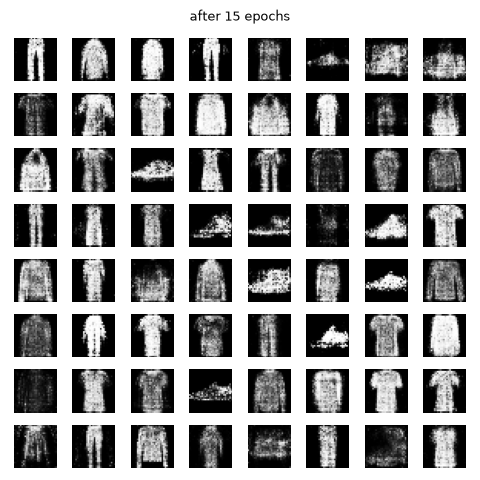

In [ ]:
from IPython.display import Image
Image('outputs/epoch_15.png')

Look at the losses first: from epoch 1 to epoch 15 they hardly move, both around 1.0, and the discriminator keeps
scoring real photos around 0.6 and fakes around 0.4. Now look at the pictures: after one epoch, grey smudges; after 15,
recognizable trousers, shirts, dresses, sneakers and bags. That's section 17.1.2's point in practice: in a two-player
game the losses stay balanced while both players improve, so **the loss tells you nothing about quality**. You need
another way to measure.

## Step 3: a judge

The judge is a small CNN trained on real Fashion-MNIST, completely separate from the GAN. It answers three questions
about 1,000 generated images, compared with 1,000 real test photos:

- **Quality:** for what share of images is the judge at least 90% sure what they are?
- **Variety:** how many kinds of clothes appear? The "effective number" of kinds is 10 if all ten are equally common and 1
  if only one kind appears, which would be mode collapse.
- **Copying:** how far is each image from its nearest training photo? A GAN that memorized its training set would score
  close to zero.

In [ ]:
%%writefile evaluate.py
"""Judge the GAN the same way a person would want: are the clothes recognizable, are all 10 kinds made, and are they
new rather than copies? A separate CNN trained on real Fashion-MNIST is the judge."""
import math
import torch
import torch.nn.functional as F
from torch import nn
from data import load, CLASSES
from models import generator, Z

torch.manual_seed(0)
x, y = load("train"); xt, yt = load("t10k")
judge = nn.Sequential(nn.Unflatten(1, (1, 28, 28)), nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                      nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 49, 10))
opt = torch.optim.Adam(judge.parameters(), 1e-3)
for epoch in range(2):
    order = torch.randperm(len(x))
    for s in range(0, len(x), 128):
        i = order[s:s + 128]
        loss = F.cross_entropy(judge(x[i] * 2 - 1), y[i]); opt.zero_grad(); loss.backward(); opt.step()
judge.eval()
with torch.no_grad():
    print(f"judge accuracy on real test clothes: {(judge(xt * 2 - 1).argmax(1) == yt).float().mean():.3f}\n")

G = generator(); G.load_state_dict(torch.load("generator.pt")); G.eval()


def report(name, imgs):
    with torch.no_grad():
        p = torch.softmax(judge(imgs), 1)
    sure = (p.max(1).values > 0.9).float().mean().item()
    counts = torch.bincount(p.argmax(1), minlength=10)
    q = counts.float() / counts.sum()
    variety = math.exp(-(q[q > 0] * q[q > 0].log()).sum().item())       # effective number of kinds, max 10
    nearest = torch.cdist(imgs, x[:20000] * 2 - 1).min(1).values.median().item()
    print(f"{name:22s} judge sure {sure:4.0%}   kinds of clothes {variety:4.1f} of 10   "
          f"distance to nearest training image {nearest:5.1f}")
    return counts


with torch.no_grad():
    fake = G(torch.randn(1000, Z, generator=torch.Generator().manual_seed(3)))
report("real test images", xt[:1000] * 2 - 1)
counts = report("GAN samples", fake)
print("\nwhat the GAN makes, according to the judge:")
print("  " + ", ".join(f"{CLASSES[k]} {counts[k].item()}" for k in counts.argsort(descending=True)))

Writing evaluate.py


In [ ]:
!python evaluate.py

judge accuracy on real test clothes: 0.888

real test images       judge sure  68%   kinds of clothes  9.9 of 10   distance to nearest training image   7.5
GAN samples            judge sure  26%   kinds of clothes  9.5 of 10   distance to nearest training image   8.9

what the GAN makes, according to the judge:
  shirt 173, coat 142, T-shirt 112, sneaker 107, pullover 102, dress 93, trouser 74, bag 67, ankle boot 66, sandal 64


- **No mode collapse.** The GAN makes all ten kinds, 9.5 out of 10 effective kinds, close to the real 9.9. Shirts and
  coats are a little over-represented, sandals and boots a little under.
- **No copying.** Its images are about as far from the training set as real test photos are (8.9 against 7.5).
- **Quality is the weak point.** The judge is confident about 26% of the samples, against 68% of real photos. The shapes
  are right, but the texture is grainy, and a judge trained on clean photos hesitates.

Fully connected layers have to learn every pixel position separately. The deep convolutional GAN of section 17.2 (figure
17.4) grows images with transpose convolutions instead, and that's the first thing to try if you want sharper clothes.

## Step 4: write the README and publish

In [ ]:
%%writefile README.md
# A GAN that draws clothes

A generative adversarial network written in PyTorch (MLP generator and discriminator, non-saturating loss) trained on
Fashion-MNIST, and evaluated by a separate CNN "judge" for quality, variety (mode collapse) and novelty.

![after 15 epochs](outputs/epoch_15.png)

## Results (1,000 generated images, judged by a CNN with 88.8% test accuracy)

| | judge at least 90% sure | kinds of clothes (effective, of 10) | distance to nearest training image |
|---|---|---|---|
| real test images | 68% | 9.9 | 7.5 |
| GAN samples | 26% | 9.5 | 8.9 |

The GAN makes all ten kinds of clothes (no mode collapse) and doesn't copy training images, but its samples are grainy:
the judge is confident about far fewer of them than about real photos.

## Run it

```bash
pip install -r requirements.txt
python train.py      # about 3 minutes on a laptop CPU
python evaluate.py
```

## What I learned

- GAN losses don't measure image quality: both stayed near 1.0 while the pictures improved a lot.
- An independent judge makes quality, variety and copying measurable.
- A small fully connected GAN gets the shapes right; sharp detail needs convolutional networks and longer training.

Based on chapter 17 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Fashion-MNIST GAN with an independent judge for quality, variety and copying"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/fashion-gan.git
git push -u origin main
```

## Make it yours

- **A convolutional GAN.** Replace both networks with small convolutional ones (transpose convolutions in the generator,
  as in figure 17.4). How much does "judge sure" improve?
- **Cause mode collapse.** Train the discriminator much less (one step every 5 generator steps). Does the number of kinds
  fall?
- **A conditional GAN.** Give both networks the label too (section 17.1) and draw a chosen kind of clothes.
- **Walk the latent space.** Pick two random `z`, interpolate between them in 8 steps, and draw the images. Does a shirt
  morph smoothly into a trouser?

## On your CV

> **Fashion GAN with an independent judge** (PyTorch): generative adversarial network trained on Fashion-MNIST, evaluated
> by a separately trained CNN for quality, variety and memorization; showed no mode collapse (9.5 of 10 effective
> classes) and no copying, with 26% of samples confidently recognized vs 68% of real images.
> github.com/YOUR-USERNAME/fashion-gan

## Check yourself

- [ ] You can explain why `fake.detach()` is needed in the discriminator step.
- [ ] You can explain why the losses stayed flat while the images improved.
- [ ] You can describe how your judge would detect mode collapse.